In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
# from ipynb.fs.full.preprocessing import combine_the_data, dict_the_data 
from ipynb.fs.full.model import build_nn_model, train_model, plot_loss, plot_mae, evaluate_model 

I0000 00:00:1793637656.904366  185625 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793637656.934085  185625 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793637657.579885  185625 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


<h3>Importing The Data

,Unnamed: 0,point,time,x,y,x_rb,y_rb,s0,s1,s2,...,track_cy,track_radius,roi_x_min,roi_y_min,roi_x_max,roi_y_max,cx_rel,cy_rel,cx_mm,cy_mm
0,0,0.0,1.2720,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,260.0,6.0,154.0,120.0,434.0,400.0,0.0,0.0,0.000000,0.000000
1,1,1.0,2.6999,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,260.0,6.0,154.0,120.0,434.0,400.0,0.0,0.0,0.000000,0.000000
2,2,0.0,23.0354,1.2,1.2,1.200031,1.2,6144.0,-8393.0,2249.0,...,72.0,6.0,-60.0,-68.0,220.0,212.0,-214.0,-188.0,1.945455,1.709091
3,3,1.0,25.1267,1.1,1.2,1.099897,1.2,6144.0,-7949.0,1805.0,...,76.0,6.0,-46.0,-64.0,234.0,216.0,-200.0,-184.0,1.818182,1.672727
4,4,2.0,27.2019,1.0,1.2,0.999989,1.2,6144.0,-7506.0,1362.0,...,76.0,6.0,-32.0,-64.0,248.0,216.0,-186.0,-184.0,1.690909,1.672727


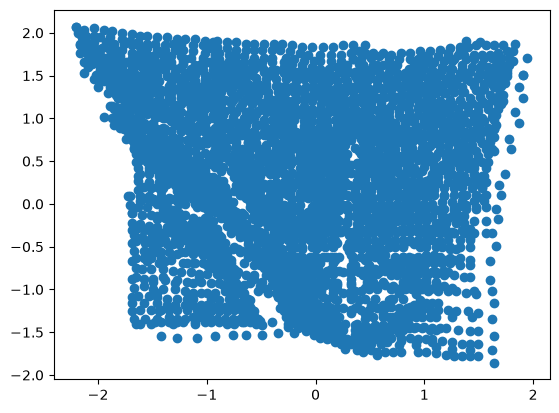

In [2]:
data_concat = pd.read_csv("processed_data/16Oct_data_corrected.csv")
display(data_concat.head())
data_concat.dtypes
plt.scatter(data_concat["cx_mm"], data_concat["cy_mm"])


<h3>Correcting The Data - NANs - Just removing currently 

In [3]:
data_concat.isna().sum()

Unnamed: 0        0
point             0
time              0
x                 0
y                 0
x_rb              0
y_rb              0
s0                0
s1                0
s2                0
strain            0
frame_id          0
n_circles         0
cx              133
cy              133
radius          133
detected          0
track_cx          2
track_cy          2
track_radius      2
roi_x_min         2
roi_y_min         2
roi_x_max         2
roi_y_max         2
cx_rel          133
cy_rel          133
cx_mm           133
cy_mm           133
dtype: int64

In [4]:
data_concat = data_concat.dropna()

In [5]:
print(data_concat["s1"].dtype)

float64


<h3>Basic MLP - Inverse 

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.metrics import r2_score

import tensorflow as tf
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

In [7]:
#split into training and testing 
dataset = data_concat[["cx_mm", "cy_mm", "s0", "s1", "s2"]].reset_index(drop=True) #reset indexes as multiple datapoints combined
inputs = data_concat[["cx_mm", "cy_mm"]]
outputs = data_concat[["s0", "s1", "s2"]]

train_dataset = dataset.sample(frac=0.8, random_state=0)
test_dataset = dataset.drop(train_dataset.index)

print(test_dataset)

         cx_mm     cy_mm      s0      s1      s2
0     0.000000  0.000000     0.0     0.0     0.0
3     1.818182  1.672727  6144.0 -7949.0  1805.0
7     1.163636  1.600000  6144.0 -6176.0    32.0
21   -1.054545  1.636364  6144.0    32.0 -6176.0
24   -1.545454  1.745454  6144.0  1362.0 -7506.0
...        ...       ...     ...     ...     ...
3534  0.018182 -1.000000 -4608.0   530.0  4078.0
3535  0.163636 -1.000000 -4608.0    87.0  4521.0
3538  0.709091 -0.963636 -4608.0 -1687.0  6295.0
3544  0.381818 -1.200000 -5120.0  -100.0  5220.0
3555 -0.600000 -0.927273 -5120.0  4777.0   343.0

[712 rows x 5 columns]


In [8]:
train_dataset.describe().transpose()[['mean', 'std']]

,mean,std
cx_mm,-0.157244,0.972635
cy_mm,0.249888,0.973730
s0,9.970526,3520.730583
s1,-45.902807,3536.287607
s2,35.932281,3559.080536


In [9]:
train_features = train_dataset.copy()
test_features = test_dataset.copy()

train_labels = pd.concat([train_features.pop(x) for x in ['s0', 's1', 's2']], axis=1)
test_labels = pd.concat([test_features.pop(x) for x in ['s0', 's1', 's2']], axis=1)

train_features

,cx_mm,cy_mm
1009,0.127273,1.236364
2248,-1.218182,0.636364
2651,-0.290909,-1.145455
117,-0.690909,1.127273
2183,-1.272727,0.400000
...,...,...
46,1.218182,1.418182
747,1.181818,1.290909
3254,0.963636,1.127273
753,1.709091,1.381818


In [10]:
#can do this with a normalisation layer
normalizer = tf.keras.layers.Normalization(axis=-1)
#Then, fit the state of the preprocessing layer to the data by calling Normalization.adapt:
normalizer.adapt(np.array(train_features))
#Calculate the mean and variance, and store them in the layer:
print(normalizer.mean.numpy())


[[-0.15724401  0.24988836]]


W0000 00:00:1793637657.921544  185625 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [11]:
#When the layer is called, it returns the input data, with each feature independently normalized:
first = np.array(train_features[:1])

with np.printoptions(precision=2, suppress=True):
  print('First example:', first)
  print()
  print('Normalized:', normalizer(first.astype(np.float32)).numpy())

First example: [[0.13 1.24]]

Normalized: [[0.29 1.01]]


In [13]:
dnn_standard_model = build_nn_model(train_features.shape[1], train_labels.shape[1], normalizer)
dnn_standard_model.summary() #investigate 

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 2)              │             5 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,536 (25.54 KB)

 Trainable params: 6,531 (25.51 KB)

 Non-trainable params: 5 (24.00 B)

In [15]:
dnn_standard_history = train_model(dnn_standard_model, train_features, train_labels, verbose=1)

Epoch 1/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 12450828.0000 - mae: 2975.4365 - val_loss: 12709762.0000 - val_mae: 3009.4492
Epoch 2/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 12270621.0000 - mae: 2953.2966 - val_loss: 12217531.0000 - val_mae: 2949.0818
Epoch 3/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 11114185.0000 - mae: 2804.3804 - val_loss: 10034009.0000 - val_mae: 2654.8530
Epoch 4/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 8236577.0000 - mae: 2363.6360 - val_loss: 6442202.5000 - val_mae: 2041.7222
Epoch 5/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 4698471.0000 - mae: 1693.3068 - val_loss: 2962854.5000 - val_mae: 1286.1370
Epoch 6/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1846585.7500 - mae: 994.2805 - val_loss: 993191.3125 - val_mae: 720.2810
Epoch 7/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 631050.6875 - mae: 606.3922 - val_loss: 502450.0625 - val_mae: 530.1053
Epoch 8/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - los

191018.859375


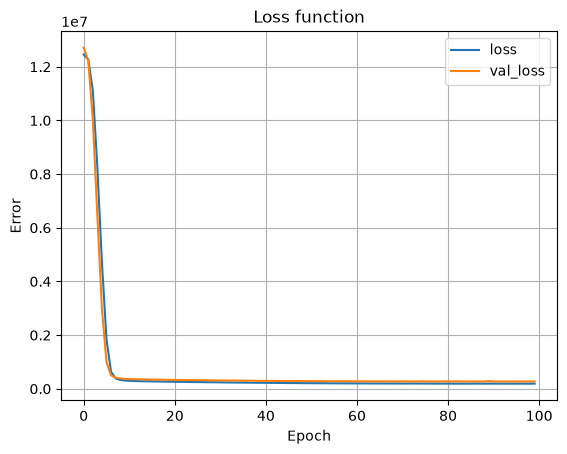

In [17]:
plot_loss(dnn_standard_history)
print(dnn_standard_history.history['loss'][-1])

302.1250915527344


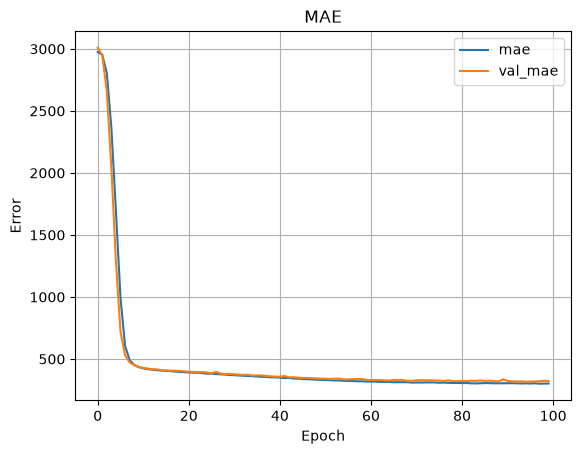

In [19]:
plot_mae(dnn_standard_history)
print(dnn_standard_history.history['mae'][-1])

In [20]:
test_results_dnn_standard = dnn_standard_model.evaluate(test_features, test_labels, verbose=0)
test_results_dnn_standard

[223158.90625, 290.7392578125]

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
712 2136


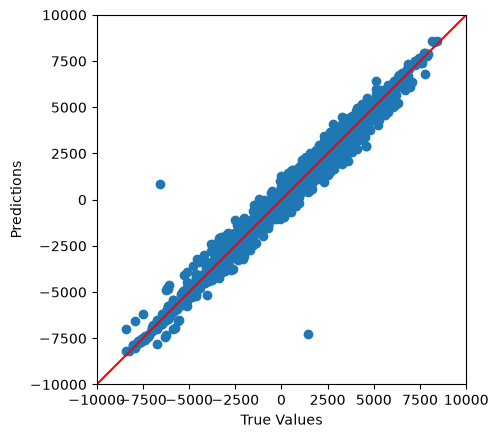

In [21]:
#make predictions with dnn model
test_predictions = dnn_standard_model.predict(test_features).flatten() #flattened - want them in 3s

a = plt.axes(aspect='equal')
plt.scatter(test_labels, test_predictions)
plt.xlabel('True Values')
plt.ylabel('Predictions')
lims = [-10000, 10000]
plt.xlim(lims)
plt.ylim(lims)
_ = plt.plot(lims, lims, color="red")
plt.title("")
print(len(test_labels), len(test_predictions))

In [22]:
#make predictions with dnn model
test_predictions_not_flattened = dnn_standard_model.predict(test_features)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 712us/step


Text(0.5, 0.98, '16th Oct Test Predictions not flattened')

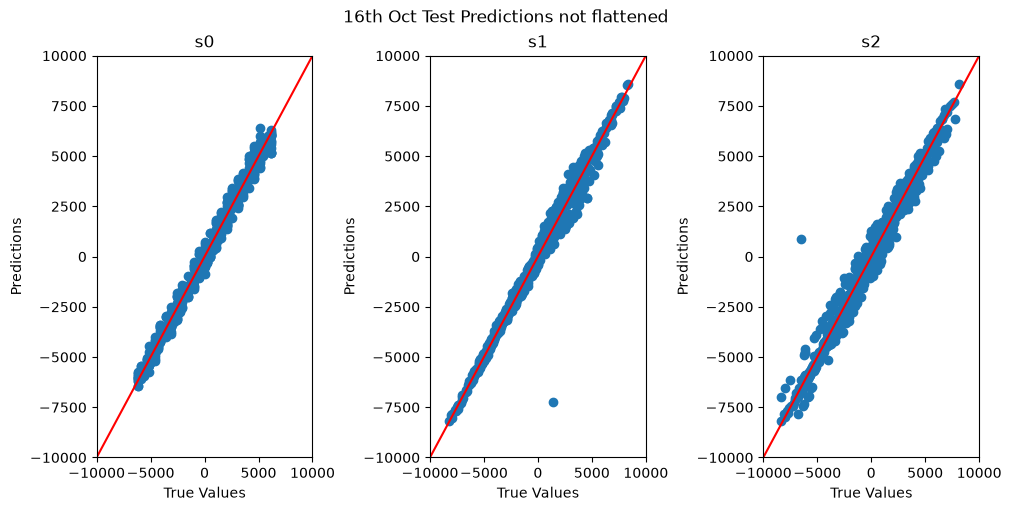

In [23]:
fig, axs = plt.subplots(1, 3, figsize=(10,5), constrained_layout=True)
for i, label in enumerate(['s0', 's1', 's2']):
    axs[i].scatter(test_labels[label], test_predictions_not_flattened[:, i])
    lims = [-10000, 10000]
    axs[i].set_xlabel('True Values')
    axs[i].set_ylabel('Predictions')
    axs[i].set_xlim(lims)
    axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")
    axs[i].set_title(label)
fig.suptitle("16th Oct Test Predictions not flattened")

In [25]:
evaluate_model("Standard NN Inverse", test_labels, test_predictions_not_flattened)
evaluate_model("Standard NN Inverse", test_labels.to_numpy().flatten(), test_predictions)


Standard NN Inverse Results:
  Overall R2:  0.9820
  Weighted R2: 0.9822

Standard NN Inverse Results:
  Overall R2:  0.9822
  Weighted R2: 0.9822


(0.9821875588060688, 0.9821875588060688)

Very high r2 score. Higher than expected from basic MLP with no history.

Predictions are also pretty good, but there are some that are wildly off. 

Probably overfitting to this data. 

<h1> Testing with data from 27Oct - Dataset 2

In [26]:
mesh0045_27Oct = pd.read_csv("processed_data/27Oct_0045_mesh.csv")
mesh0045_27Oct_nonans = mesh0045_27Oct.dropna()

input_27Oct_45 = mesh0045_27Oct_nonans[["cx_mm","cy_mm"]]
true_values_27Oct_45 = mesh0045_27Oct_nonans[["s0","s1","s2"]]

pred_27Oct_45_not_flat = dnn_standard_model.predict(input_27Oct_45)

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 990us/step


Text(0.5, 0.98, 'Predictions on scan 0045_dmesh from 27Oct Dataset. Using NN trained on 16thOct Dataset')

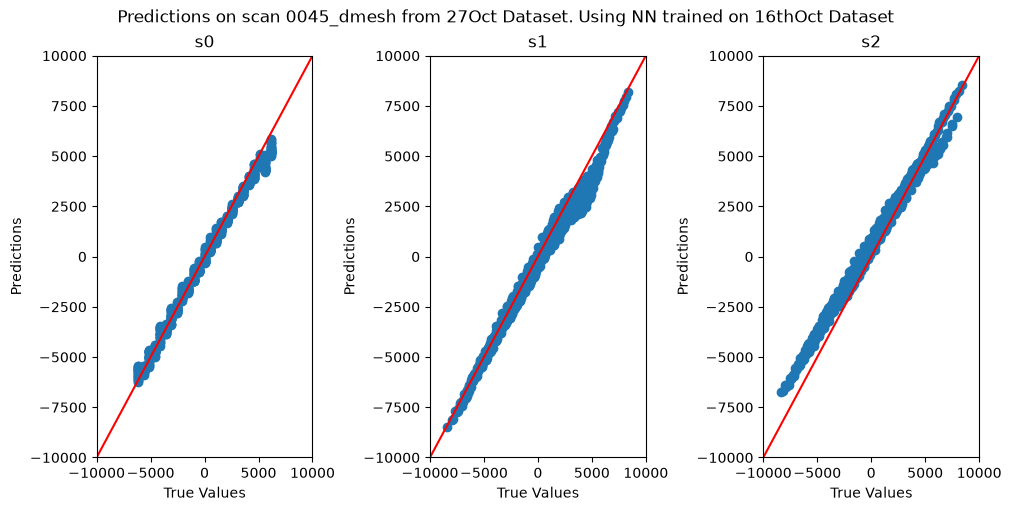

In [27]:
fig, axs = plt.subplots(1, 3, figsize=(10,5), constrained_layout=True)
for i, label in enumerate(['s0', 's1', 's2']):
    axs[i].scatter(true_values_27Oct_45[label], pred_27Oct_45_not_flat[:, i])
    lims = [-10000, 10000]
    axs[i].set_xlabel('True Values')
    axs[i].set_ylabel('Predictions')
    axs[i].set_xlim(lims)
    axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")
    axs[i].set_title(label)
fig.suptitle("Predictions on scan 0045_dmesh from 27Oct Dataset. Using NN trained on 16thOct Dataset")

In [28]:
#evaluate with first scan of 27th Oct

evaluate_model("Standard NN Inverse on 27Oct Dataset 45", true_values_27Oct_45, pred_27Oct_45_not_flat)



Standard NN Inverse on 27Oct Dataset 45 Results:
  Overall R2:  0.9713
  Weighted R2: 0.9713


(0.9713344573974609, 0.971327543258667)

In [29]:
display(pred_27Oct_45_not_flat)
display(true_values_27Oct_45)
np.savetxt("16Oct_NN_Pred_27Oct_Scan0045", pred_27Oct_45_not_flat, delimiter=',')

array([[ 5853.78  , -8497.79  ,  2642.866 ],
       [ 5821.435 , -8142.035 ,  2320.6704],
       [ 5703.2925, -7754.9355,  2052.7944],
       ...,
       [-6118.0454,  7190.2627, -1058.7314],
       [-6186.8257,  7727.3135, -1528.1617],
       [-6235.69  ,  8194.519 , -1948.4005]],
      shape=(593, 3), dtype=float32)

,s0,s1,s2
0,6144.0,-8393.0,2249.0
1,6144.0,-7949.0,1805.0
2,6144.0,-7506.0,1362.0
3,6144.0,-7063.0,919.0
4,6144.0,-6619.0,475.0
...,...,...,...
620,-6144.0,6619.0,-475.0
621,-6144.0,7063.0,-919.0
622,-6144.0,7506.0,-1362.0
623,-6144.0,7949.0,-1805.0


<h4> The following code was for understanding why so many values had been predicted as near to 0 when the true values were not. </h4>
Turns out, the cx/cy values were nans. 

R2 was ~ 0.91 with nans.

R2 is now ~ 0.966 without nans.

Still seems unbeleivably high! --> even higher than with the test data --> maybe because it's only one scan?

In [30]:
np.where(pred_27Oct_45_not_flat[:,0] == 0)

(array([], dtype=int64),)

In [31]:
# pred_27Oct_45_not_flat[:,0].any() < 1 
# pred_27Oct_45_not_flat[:,0].any() > -1
print(np.any(pred_27Oct_45_not_flat[:,0] == 3.279613494873046875e+00 ) )
x = pred_27Oct_45_not_flat[:,0]
zero_preds = np.argwhere(x == 3.279613494873046875e+00)
print(zero_preds)

False
[]


In [32]:
true_s0_values = []
input_cx_values = []
input_cy_values = []
for i in zero_preds:
    true_s0_values.append(true_values_27Oct_45["s0"][i])
    input_cx_values.append(input_27Oct_45["cx_mm"][i])
    input_cy_values.append(input_27Oct_45["cy_mm"][i])
true_s0_values
input_cx_values
input_cy_values

[]

<h3> Try with all the data from 27th Oct?

<h2> Predicting for normal square



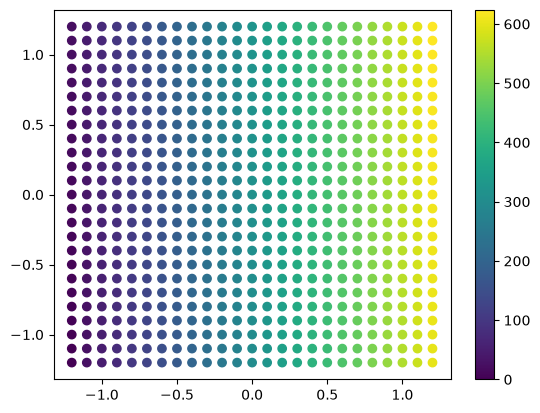

In [33]:
x = np.linspace(-1.2, 1.2, 25)
y = x
xy = []
for i in x:
    for j in y:
        xy.append([i,j])

xy_np = np.array(xy)
plt.scatter(xy_np[:,0], xy_np[:,1], c=range(0, 625))
plt.colorbar()

In [34]:
square_predictions = dnn_standard_model.predict(xy_np)

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


In [35]:
print(square_predictions)
np.savetxt("16Oct_NN_Pred_mesh_scan", square_predictions, delimiter=',')

[[-5522.044   7026.9805 -1494.7552]
 [-5267.6636  6840.1055 -1563.0918]
 [-4997.7866  6650.6255 -1644.1387]
 ...
 [ 2972.5232 -5473.239   2500.7793]
 [ 3381.429  -5621.082   2240.721 ]
 [ 3784.3474 -5773.1597  1990.9055]]


<h2>This data is not in the same order as the snake scan - try again 

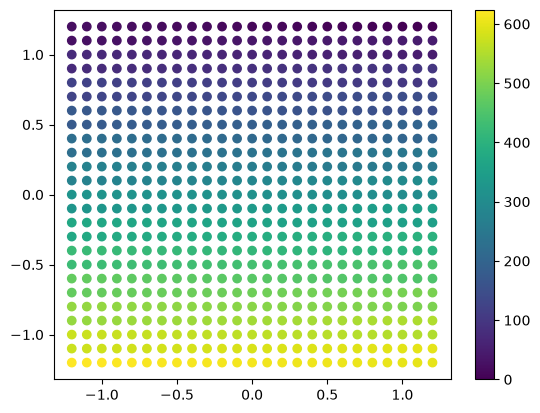

In [36]:
plt.scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
plt.colorbar()

In [37]:
snake_predictions = dnn_standard_model.predict(mesh0045_27Oct[["x", "y"]])

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 800us/step


In [38]:
snake_predictions.dtype

dtype('float32')

In [39]:
print(snake_predictions)
np.savetxt("predictions/16Oct_MLP_Pred_snake_mesh.csv", snake_predictions, delimiter=',')

[[ 3784.3474 -5773.1597  1990.9055]
 [ 3797.7375 -5510.3     1715.9152]
 [ 3810.3684 -5245.8086  1440.0446]
 ...
 [-5491.101   6438.95    -935.7124]
 [-5502.4634  6746.8853 -1233.4747]
 [-5522.044   7026.9805 -1494.7552]]
